# Blood-brain barrier prediction

Compare Morgan fingerprints with a small bond-aware graph neural network on MoleculeNet BBBP. The unit is one molecule; the output is a probability of the curated penetration label (`p_np=1`). This is a benchmark experiment, with no claim of drug safety, biological causality or clinical suitability.

The fixed split seed is **2026**; GNN seeds are **17, 29, 43** on the same partitions. Hyperparameters, checkpoints and thresholds use training/validation data only. Test results are computed after all eight final models are frozen. PR-AUC means **average precision** throughout.

Run every cell from the project directory. The first run downloads BBBP through PyTorch Geometric. A complete local run is reused only when code, settings and artifact hashes match; absent checkpoints trigger training.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='`torch.jit.script` is deprecated.*', category=FutureWarning)
warnings.filterwarnings('ignore', message='IProgress not found.*')
from pathlib import Path
import inspect
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image, Markdown
from molecular_utils import CONFIG, SEEDS, MolecularGNN, CategoricalEncoder, seed_everything
from run_experiments import run_pipeline
seed_everything(2026)
ROOT = Path.cwd()
OUT = ROOT / 'outputs'
TABLES = OUT / 'tables'
FIG = OUT / 'figures'
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', 20)
print('PyTorch:', torch.__version__, '| MPS available:', torch.backends.mps.is_available())
print('Fixed configuration:', json.dumps(CONFIG, indent=2))

PyTorch: 2.15.0 | MPS available: True
Fixed configuration: {
  "hidden": 64,
  "layers": 3,
  "dropout": 0.2,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "batch_size": 64,
  "max_epochs": 80,
  "patience": 15,
  "fingerprint_radius": 2,
  "fingerprint_bits": 2048,
  "baseline_C": [
    0.01,
    0.1,
    1.0,
    10.0
  ],
  "split_seed": 2026,
  "model_seeds": [
    17,
    29,
    43
  ],
  "threshold_metric": "balanced_accuracy",
  "checkpoint_metric": "validation_roc_auc"
}


## Run the frozen experiment protocol

Three GINE layers use categorical atom and bond embeddings, residual updates and mean graph pooling. Morgan logistic regression compares `C = 0.01, 0.1, 1, 10`. GNNs train for at most 80 epochs, with validation ROC-AUC checkpointing and patience 15. Each model uses its own validation balanced-accuracy threshold. A saved evaluation lock precedes all test predictions.

In [2]:
summary = run_pipeline(reuse_results=True)
print('Device:', summary['device'])
display(pd.Series(summary['device_benchmark'], name='Seconds per training step').to_frame())
print('Recorded experiment runtime (minutes):', round(summary['timings']['total_seconds'] / 60, 2))

Reusing complete hash-validated experiment, without re-evaluating test sets.


Device: cpu


,Seconds per training step
cpu,0.008331
mps,0.008439


Recorded experiment runtime (minutes): 1.58


## Inspect and clean the molecules

Canonical isomeric SMILES identify exact molecule duplicates, including different original SMILES. Keep one representative when labels agree; remove every member of conflicting-label groups. Invalid/empty molecules and non-finite labels are excluded before splitting. The raw-file audit also counts invalid records skipped inside the PyG loader. Canonicalization does not merge salts, tautomers or different protonation states.

raw_records                                                                                          2050
loader_records                                                                                       2039
loader_excluded_records                                                                                11
invalid_or_empty_raw                                                                                   11
invalid_raw_indices                                 [59, 61, 391, 614, 642, 645, 646, 647, 648, 649, 685]
nonfinite_raw_labels                                                                                    0
invalid_or_empty_loaded                                                                                 0
nonfinite_loaded_labels                                                                                 0
duplicate_groups                                                                                       60
duplicate_records                             

,atoms,bonds
count,1965.000000,1965.000000
mean,24.223410,26.128244
std,10.668036,11.791892
min,2.000000,1.000000
25%,18.000000,19.000000
50%,23.000000,25.000000
75%,29.000000,31.000000
max,132.000000,145.000000


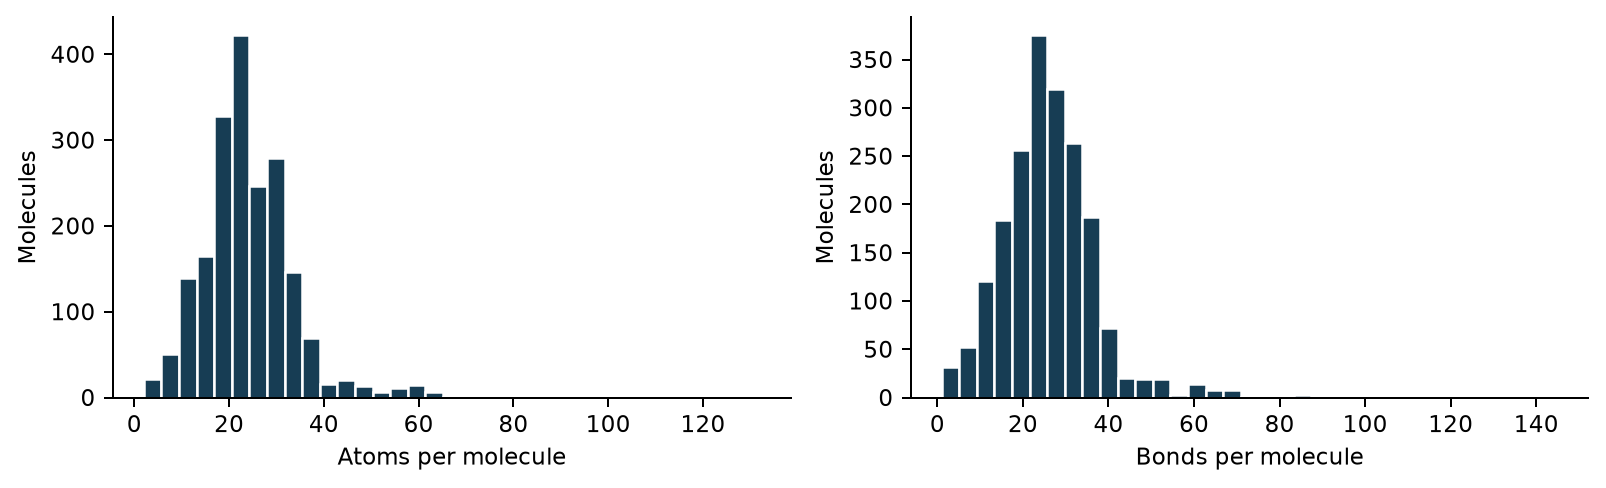

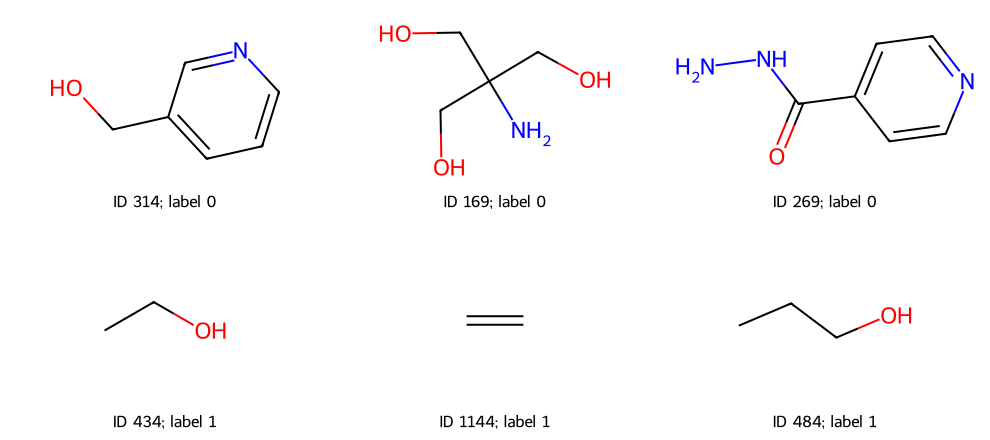

,record_id,canonical_smiles,label
0,314,OCc1cccnc1,0
1,169,NC(CO)(CO)CO,0
2,269,NNC(=O)c1ccncc1,0
3,434,CCO,1
4,1144,C=C,1
5,484,CCCO,1


In [3]:
display(pd.Series({k: v for k, v in summary['audit'].items() if k != 'distribution'}, name='Audit'))
display(pd.DataFrame(summary['audit']['distribution']))
display(Image(filename=str(FIG / 'size_distributions.png')))
examples = pd.read_csv(TABLES / 'examples.csv')
display(Image(filename=str(FIG / 'molecule_examples.png')))
display(examples[['record_id', 'canonical_smiles', 'label']])

## Molecular graphs and batching

Atoms are nodes; each chemical bond is stored as two directed edges. Every atom column and bond column is categorical. Independent trainable embeddings map category IDs to vectors and sum them within each atom or bond; IDs are never interpreted as continuous measurements.

Matching atom indices connect the chemical drawing with its node-edge graph. A PyG batch concatenates nodes and edges, offsets connectivity indices and provides a `batch` vector assigning each atom to a molecule.

,name,cardinality,tensor
0,atomic_num,119,x
1,chirality,9,x
2,degree,11,x
3,formal_charge,12,x
4,num_hs,9,x
5,num_radical_electrons,5,x
6,hybridization,8,x
7,is_aromatic,2,x
8,is_in_ring,2,x


,name,cardinality,tensor
0,bond_type,22,edge_attr
1,stereo,6,edge_attr
2,is_conjugated,2,edge_attr


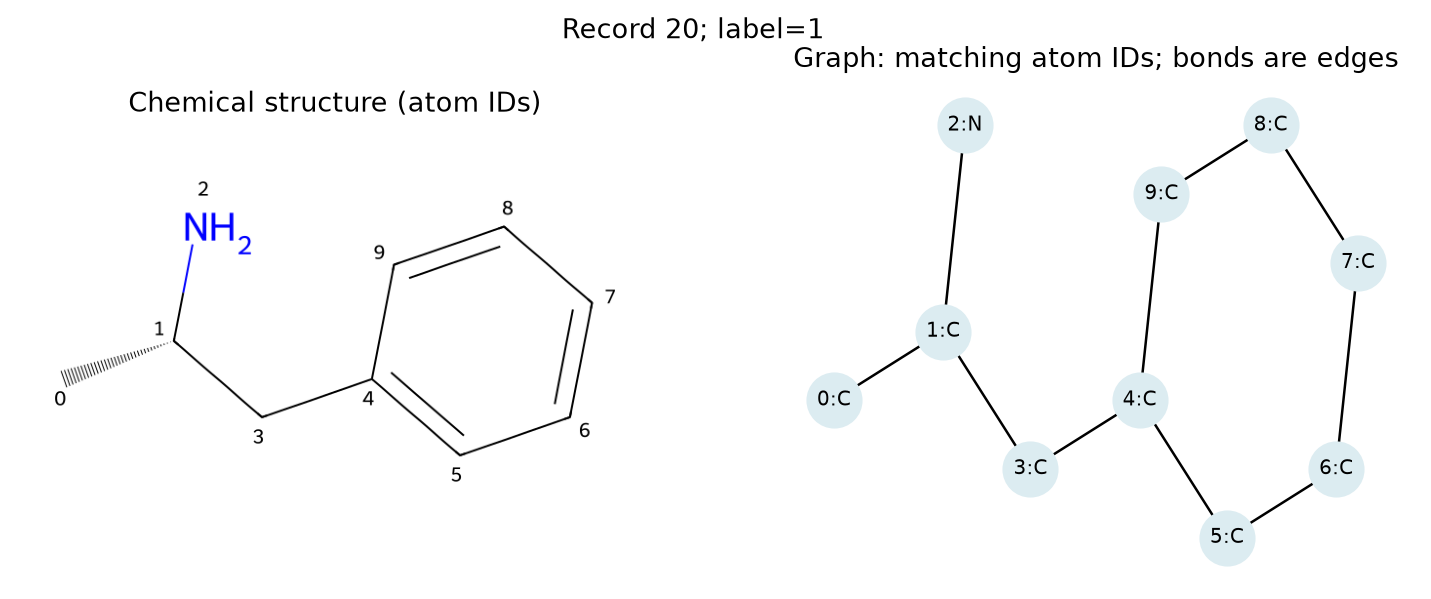

Example graph: {
  "record_id": 20,
  "smiles": "C[C@H](N)Cc1ccccc1",
  "x_shape": [
    10,
    9
  ],
  "edge_index_shape": [
    2,
    20
  ],
  "edge_attr_shape": [
    20,
    3
  ],
  "y": [
    [
      1.0
    ]
  ],
  "x_first_atom": [
    6,
    0,
    4,
    5,
    3,
    0,
    4,
    0,
    0
  ],
  "edge_attr_first_bond": [
    1,
    0,
    0
  ]
}
Batch inspection: {
  "x": [
    1522,
    9
  ],
  "edge_index": [
    2,
    3276
  ],
  "edge_attr": [
    3276,
    3
  ],
  "batch": [
    1522
  ],
  "y": [
    64,
    1
  ],
  "num_graphs": 64,
  "total_graphs_verified": 1965
}
Integrity checks: {'finite_labels': True, 'nonempty_graphs': True, 'batching_complete': True, 'splits_complete': True, 'indices_disjoint': True, 'canonical_smiles_disjoint': True, 'scaffold_groups_disjoint': True, 'test_selection_leakage': False}


In [4]:
display(pd.DataFrame(summary['feature_schema']['atom']).assign(tensor='x'))
display(pd.DataFrame(summary['feature_schema']['bond']).assign(tensor='edge_attr'))
display(Image(filename=str(FIG / 'graph_views.png')))
print('Example graph:', json.dumps(summary['graph_inspection'], indent=2))
print('Batch inspection:', json.dumps(summary['batch_inspection'], indent=2))
print('Integrity checks:', summary['assertions'])

## Random versus scaffold evaluation

The stratified random split targets 70:15:15. The scaffold split shuffles framework groups with seed 2026, sorts largest first and assigns each complete group to the subset with the largest remaining target capacity. It uses group sizes, without labels or model scores. All acyclic molecules share one empty scaffold group. Invalid structures were already removed.

Checks enforce complete coverage, pairwise-disjoint indices and canonical-SMILES non-overlap; scaffold sets must also be disjoint in the scaffold evaluation. Random splits can put close chemical analogues in training and test. A single scaffold split changes chemical composition and prevalence too, so its score difference is not a controlled causal effect.

In [5]:
display(pd.DataFrame(summary['split_summary']))
print(summary['split_method'])
print('Selection protocol:', summary['threshold_method'])

,split,subset,molecules,positive,positive_fraction,unique_scaffolds
0,random,train,1375,1050,0.763636,766
1,random,validation,295,225,0.762712,221
2,random,test,295,225,0.762712,222
3,scaffold,train,1375,1053,0.765818,466
4,scaffold,validation,295,215,0.728814,277
5,scaffold,test,295,232,0.786441,277


Scaffold groups shuffled with seed2026, stable sorted largest first, allocated to largest remaining target capacity without labels. Empty scaffold is one group.
Selection protocol: Maximum validation balanced accuracy on 181 points from0.05 to0.95; ties nearest0.5.


## Fingerprint baseline

Morgan radius-2, 2,048-bit fingerprints hash local atom environments (approximately ECFP4). Logistic regression learns only from training molecules. Inverse-frequency class weights come from training labels. Validation ROC-AUC selects C; validation balanced accuracy selects a threshold on the predeclared grid. The threshold is then fixed.

In [6]:
for split, settings in summary['baseline_selection'].items():
    print(split, {key: value for key, value in settings.items() if key != 'candidate_results'})
    display(pd.DataFrame(settings['candidate_results']))

random_lr {'C': 1.0, 'threshold': 0.825, 'validation_roc_auc': 0.901015873015873, 'validation_balanced_accuracy': 0.8317460317460317, 'class_weight': 'balanced (training subset only)', 'solver': 'liblinear', 'max_iter': 2000, 'seed': 2026}


,C,validation_roc_auc
0,0.01,0.864889
1,0.10,0.894730
2,1.00,0.901016
3,10.00,0.895238


scaffold_lr {'C': 0.1, 'threshold': 0.6499999999999999, 'validation_roc_auc': 0.8718023255813954, 'validation_balanced_accuracy': 0.8030523255813953, 'class_weight': 'balanced (training subset only)', 'solver': 'liblinear', 'max_iter': 2000, 'seed': 2026}


,C,validation_roc_auc
0,0.01,0.865349
1,0.10,0.871802
2,1.00,0.856047
3,10.00,0.839535


## Bond-aware graph learning

A GINE message combines a neighboring atom representation with the bond embedding before aggregation. Three such layers allow local information to travel across three bonds. Residual connections and LayerNorm stabilize the updates. Mean pooling yields one vector per molecule and the MLP yields one logit.

Weighted BCE balances class contributions using the training negative/positive ratio. Adam uses learning rate 0.001 and weight decay 0.0001, batch size 64 and dropout 0.2. The highest validation ROC-AUC checkpoint is retained; no test score influences training.

class CategoricalEncoder(nn.Module):
    def __init__(self, cardinalities, hidden):
        super().__init__()
        self.embeddings = nn.ModuleList([nn.Embedding(n,hidden) for n in cardinalities])

    def forward(self, codes):
        return sum(embedding(codes[:,i]) for i,embedding in enumerate(self.embeddings))

class MolecularGNN(nn.Module):
    """Three bond-aware GINE layers with residuals and mean graph pooling."""
    def __init__(self):
        super().__init__()
        hidden = CONFIG['hidden']
        self.atom_encoder = CategoricalEncoder([len(v) for v in x_map.values()], hidden)
        self.bond_encoder = CategoricalEncoder([len(v) for v in e_map.values()], hidden)
        self.convs = nn.ModuleList([
            GINEConv(nn.Sequential(nn.Linear(hidden,hidden),nn.ReLU(),
                                   nn.Linear(hidden,hidden)),train_eps=True)
            for _ in range(CONFIG['layers'])])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in self.convs

,run_id,parameters,pos_weight,best_epoch,epochs_run,validation_roc_auc,threshold,training_seconds
1,random_gnn_17,42820.0,0.309524,80.0,80.0,0.889016,0.800,15.204681
2,random_gnn_29,42820.0,0.309524,77.0,80.0,0.895556,0.705,14.701930
3,random_gnn_43,42820.0,0.309524,80.0,80.0,0.889460,0.425,15.181967
5,scaffold_gnn_17,42820.0,0.305793,65.0,80.0,0.911105,0.580,13.968023
6,scaffold_gnn_29,42820.0,0.305793,72.0,80.0,0.913779,0.540,13.794804
7,scaffold_gnn_43,42820.0,0.305793,64.0,79.0,0.924012,0.865,13.633180


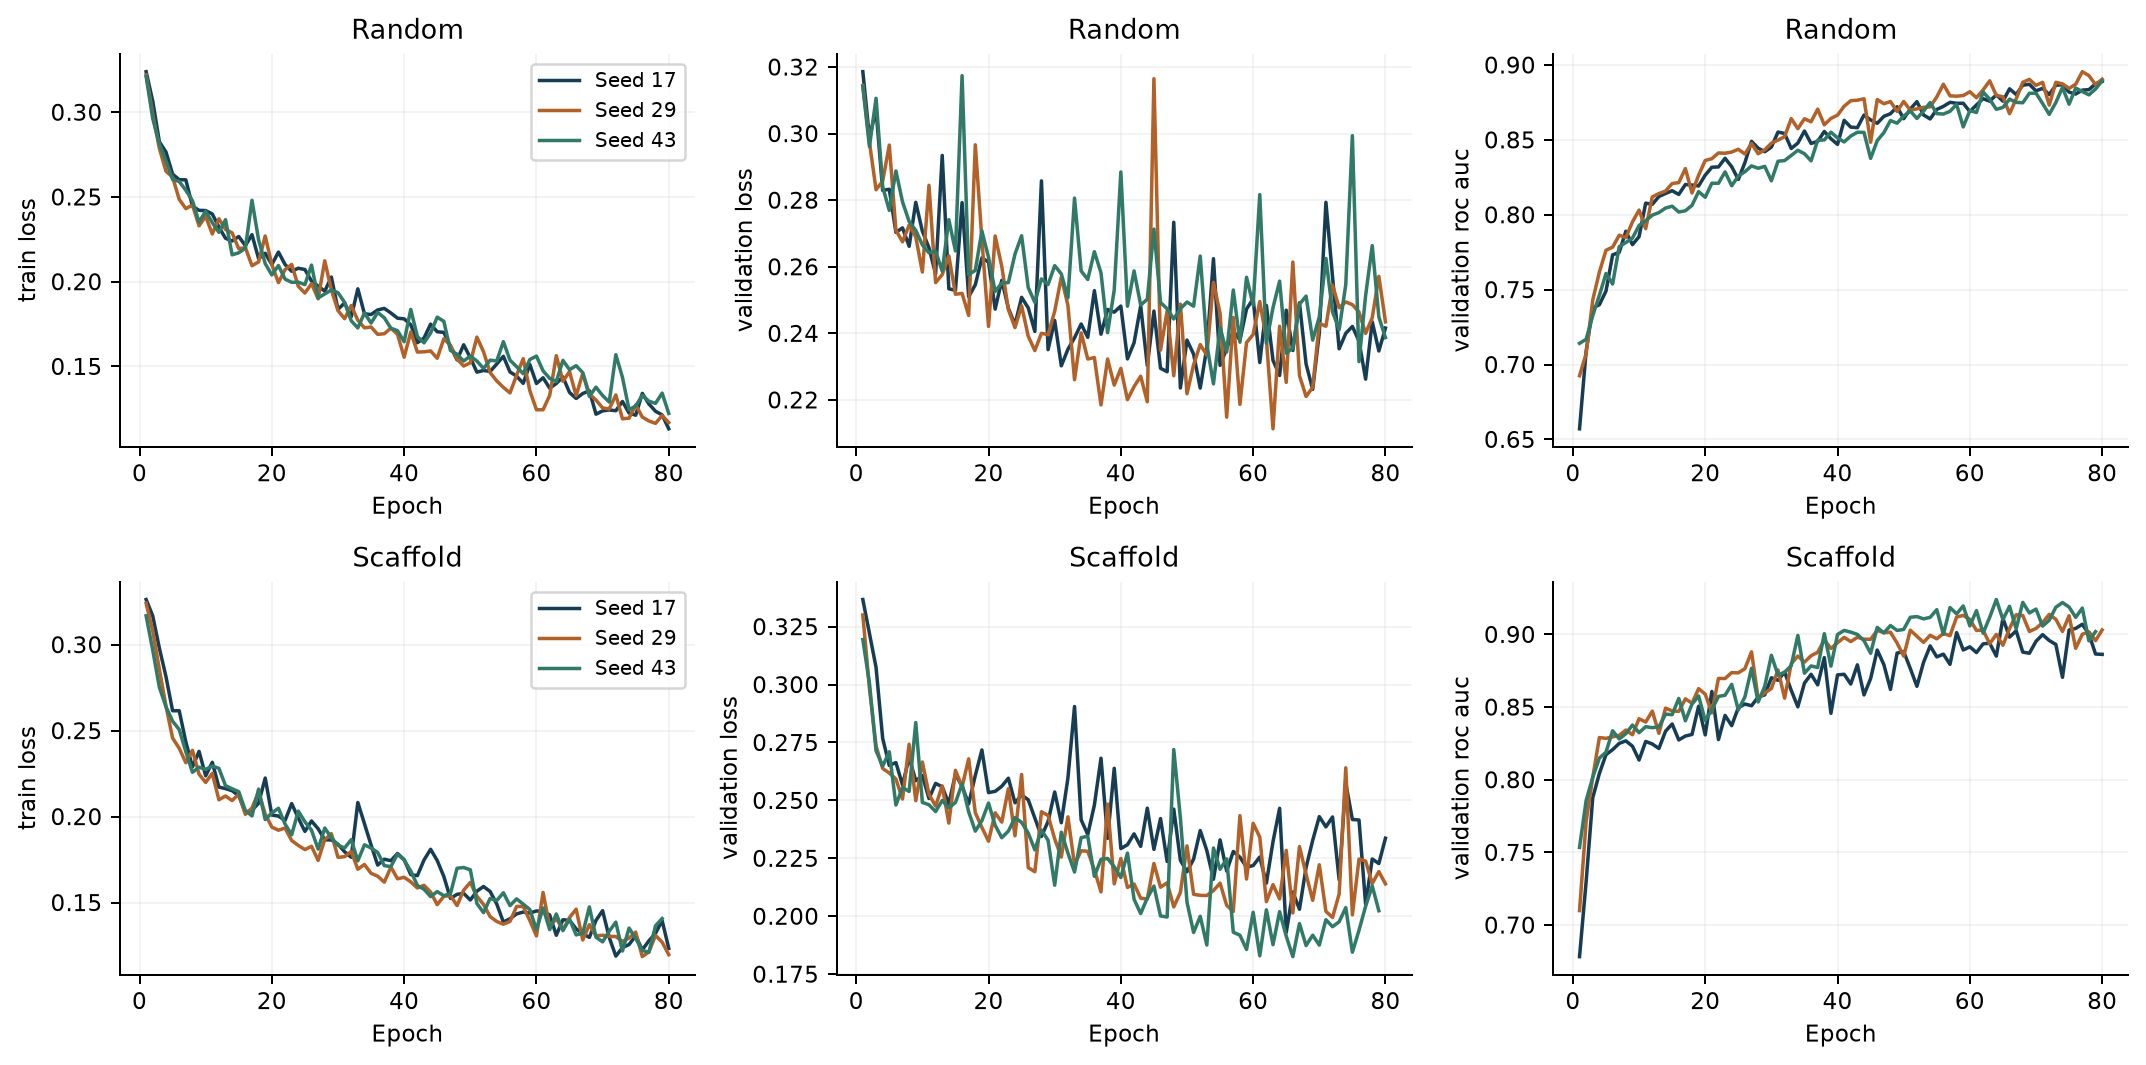

In [7]:
print(inspect.getsource(CategoricalEncoder))
print(inspect.getsource(MolecularGNN))
display(pd.DataFrame(summary['runs']).query("model == 'GINE'")[
    ['run_id', 'parameters', 'pos_weight', 'best_epoch', 'epochs_run', 'validation_roc_auc', 'threshold', 'training_seconds']])
display(Image(filename=str(FIG / 'training_curves.png')))

Training loss and validation loss reveal fitting behavior independently of final tests. Rising validation loss alongside improving training loss indicates overfitting; checkpointing retains the validation-selected model rather than the last epoch. Curves for all three seeds are shown for both fixed splits.

## Final held-out evaluation

ROC-AUC measures ranking over both classes. Average precision summarizes the precision-recall curve and depends on prevalence. Accuracy, sensitivity, specificity and F1 use each model's validation-selected threshold. Mean ± sample SD over three GNN seeds measures training variation conditional on one fixed split; it is not uncertainty over new datasets or split draws.

,model,split,run_id,threshold,roc_auc,pr_auc,accuracy,sensitivity,specificity,f1
0,Morgan LR,random,random_lr,0.825,0.9422,0.9793,0.8068,0.7733,0.9143,0.8593
1,GINE,random,random_gnn_17,0.800,0.9430,0.9812,0.7864,0.7333,0.9571,0.8397
2,GINE,random,random_gnn_29,0.705,0.9356,0.9751,0.8339,0.8044,0.9286,0.8808
3,GINE,random,random_gnn_43,0.425,0.9348,0.9752,0.8746,0.8756,0.8714,0.9142
4,Morgan LR,scaffold,scaffold_lr,0.650,0.8725,0.9589,0.7966,0.8147,0.7302,0.8630
5,GINE,scaffold,scaffold_gnn_17,0.580,0.8823,0.9489,0.8068,0.7931,0.8571,0.8659
6,GINE,scaffold,scaffold_gnn_29,0.540,0.8803,0.9510,0.8237,0.8362,0.7778,0.8818
7,GINE,scaffold,scaffold_gnn_43,0.865,0.8856,0.9434,0.7627,0.7241,0.9048,0.8276


,model,split,n_seeds,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,f1_mean,f1_std,threshold_mean,threshold_std
0,GINE,random,3,0.9378,0.0046,0.9772,0.0035,0.8316,0.0441,0.8044,0.0711,0.9190,0.0436,0.8782,0.0373,0.6433,0.1950
1,GINE,scaffold,3,0.8827,0.0027,0.9478,0.0039,0.7977,0.0315,0.7845,0.0565,0.8466,0.0642,0.8584,0.0279,0.6617,0.1772


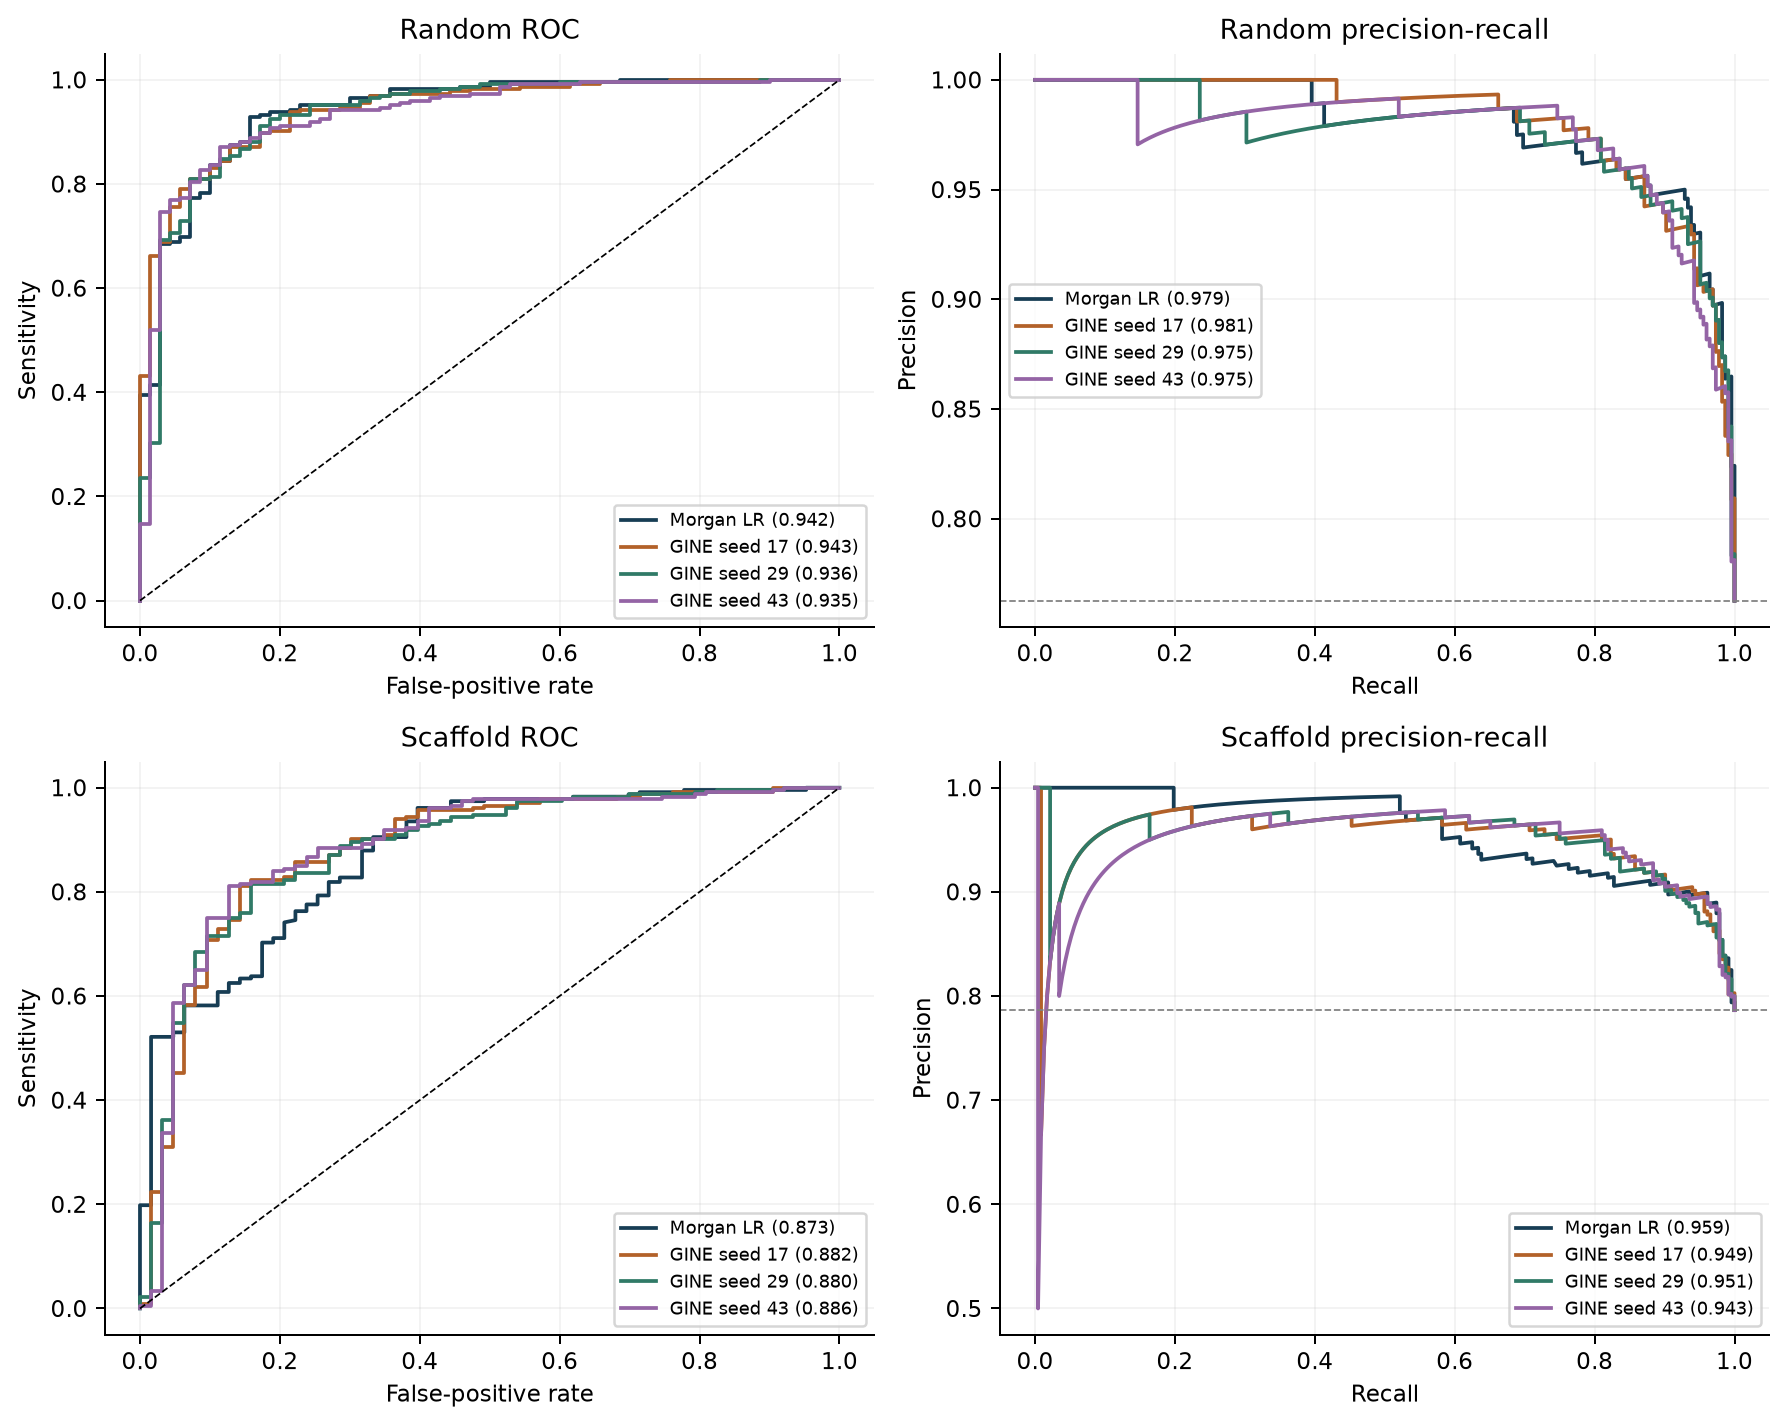

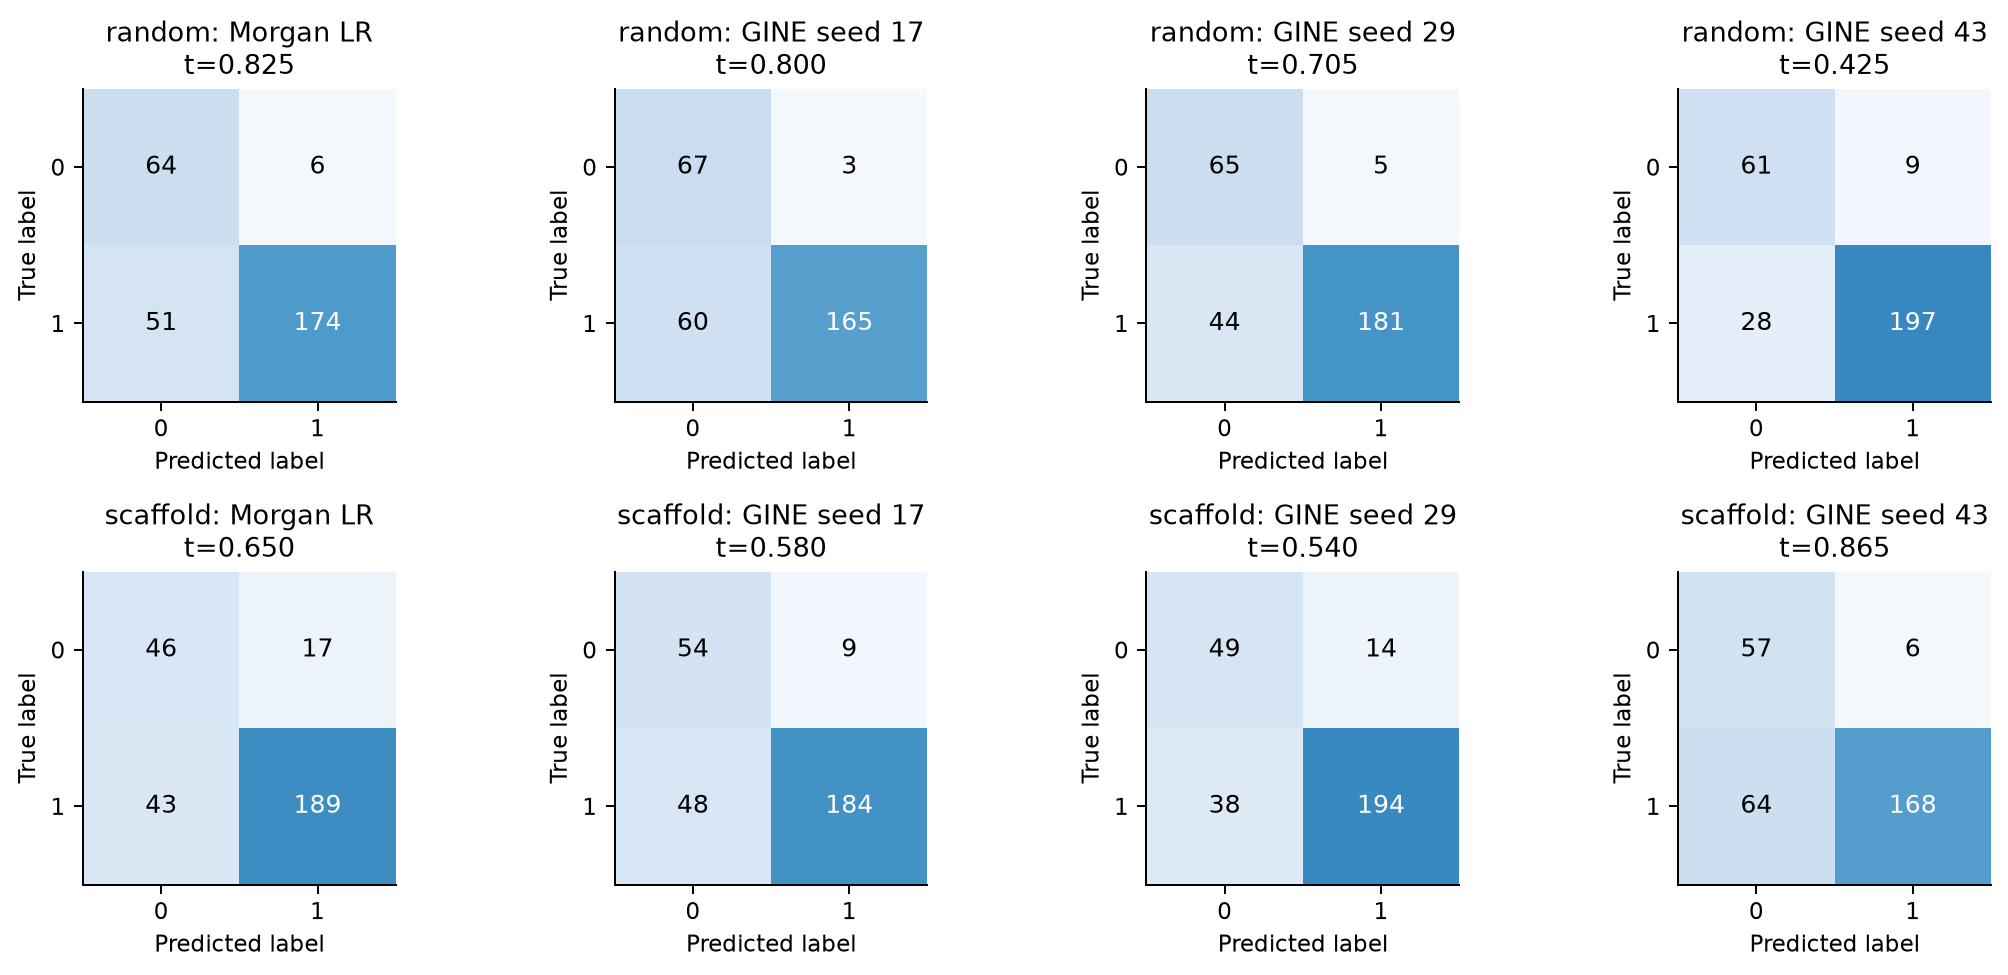

In [8]:
comparison = pd.read_csv(TABLES / 'comparison.csv')
metrics = ['roc_auc', 'pr_auc', 'accuracy', 'sensitivity', 'specificity', 'f1']
display(comparison[['model', 'split', 'run_id', 'threshold'] + metrics].round(4))
display(pd.DataFrame(summary['aggregate']).round(4))
for name in ['test_curves.png', 'confusion_matrices.png']:
    display(Image(filename=str(FIG / name)))

## Comparing the evidence

The following contrasts use the recorded, frozen test predictions. Each difference concerns this fixed benchmark partition; it is not a confidence interval or a biological conclusion.

In [9]:
for split in ['random', 'scaffold']:
    baseline = next(run for run in summary['runs'] if run['split'] == split and run['model'] == 'Morgan LR')
    gnn = next(row for row in summary['aggregate'] if row['split'] == split)
    display(Markdown(f"**{split.capitalize()}:** Morgan LR ROC-AUC {baseline['roc_auc']:.3f}; GINE {gnn['roc_auc_mean']:.3f} ± {gnn['roc_auc_std']:.3f} (sample SD across training seeds). GINE minus LR = {gnn['roc_auc_mean'] - baseline['roc_auc']:+.3f}."))
import plotly.graph_objects as go
from plotly.subplots import make_subplots
explorer = make_subplots(rows=2, cols=3, subplot_titles=metrics)
for index, metric in enumerate(metrics):
    for split, color in [('random', '#173D54'), ('scaffold', '#B26129')]:
        subset = comparison[comparison['split'] == split]
        explorer.add_trace(go.Bar(x=subset['run_id'].str.replace(split + '_', ''), y=subset[metric],
            name=split, marker_color=color, legendgroup=split, showlegend=index == 0),
            row=index // 3 + 1, col=index % 3 + 1)
explorer.update_layout(title='Frozen test evaluations', height=640, barmode='group', template='plotly_white')
explorer.update_yaxes(range=[0, 1])
explorer.write_html(OUT / 'comparison_explorer.html', include_plotlyjs=True)
print('Interactive chart: outputs/comparison_explorer.html')

**Random:** Morgan LR ROC-AUC 0.942; GINE 0.938 ± 0.005 (sample SD across training seeds). GINE minus LR = -0.004.

**Scaffold:** Morgan LR ROC-AUC 0.873; GINE 0.883 ± 0.003 (sample SD across training seeds). GINE minus LR = +0.010.

Interactive chart: outputs/comparison_explorer.html


## Scaffold-test errors and training similarity

The error analysis uses the **predeclared seed-17 scaffold GNN**, regardless of its test rank. It selects two false positives and two false negatives when available, without changing thresholds or training. The nearest training molecule is found by Morgan-fingerprint Tanimoto similarity. Both structures, true labels and model probabilities are shown. Structural similarity is descriptive evidence, not a causal explanation.

,error,record_id,smiles,canonical_smiles,label,probability,threshold,neighbor_id,neighbor_smiles,neighbor_label,neighbor_probability,tanimoto,seed
0,FP,35,CN(C)c1cc(C2=NC(N)=NN2)ccn1,CN(C)c1cc(-c2nc(N)n[nH]2)ccn1,0,0.828452,0.58,942,CN(C)c1cnccn1,1,0.975558,0.300000,17
1,FP,100,CCCCc1oc2ccccc2c1C(=O)c3cc(I)c(OCCN(CC)CC)c(I)c3,CCCCc1oc2ccccc2c1C(=O)c1cc(I)c(OCCN(CC)CC)c(I)c1,0,0.729256,0.58,452,[H+].[Cl-].CCN(CC)CCOC(=O)C(O)(c1ccccc1)c2ccccc2,1,0.653976,0.294118,17
2,FN,5,CCN1CCN(C(=O)N[C@@H](C(=O)N[C@H]2[C@H]3SCC(=C(N3C2=O)C(O)=O)CSc4nnnn4C)c5ccc(O)cc5)C(=O)C1=O,CCN1CCN(C(=O)N[C@@H](C(=O)N[C@@H]2C(=O)N3C(C(=O)O)=C(CSc4nnnn4C)CS[C@H]23)c2ccc(O)cc2)C(=O)C1=O,1,0.021432,0.58,46,Cn1nnnc1SCC2=C(N3[C@H](SC2)[C@H](NC(=O)[C@H](O)c4ccccc4)C3=O)C(O)=O,1,0.011333,0.625000,17
3,FN,6,CN(C)[C@H]1[C@@H]2C[C@H]3C(=C(O)c4c(O)cccc4[C@@]3(C)O)C(=O)[C@]2(O)C(=O)\C(=C(/O)NCN5CCCC5)C1=O,CN(C)[C@@H]1C(=O)/C(=C(/O)NCN2CCCC2)C(=O)[C@@]2(O)C(=O)C3=C(O)c4c(O)cccc4[C@@](C)(O)[C@H]3C[C@@H]12,1,0.011225,0.58,840,CN(C)C1C2CC3C(=C(O)c4c(O)cccc4C3(C)O)C(=O)C2(O)C(=O)\C(=C(/O)NCN5CCN(CCO)CC5)C1=O,0,0.017985,0.863014,17


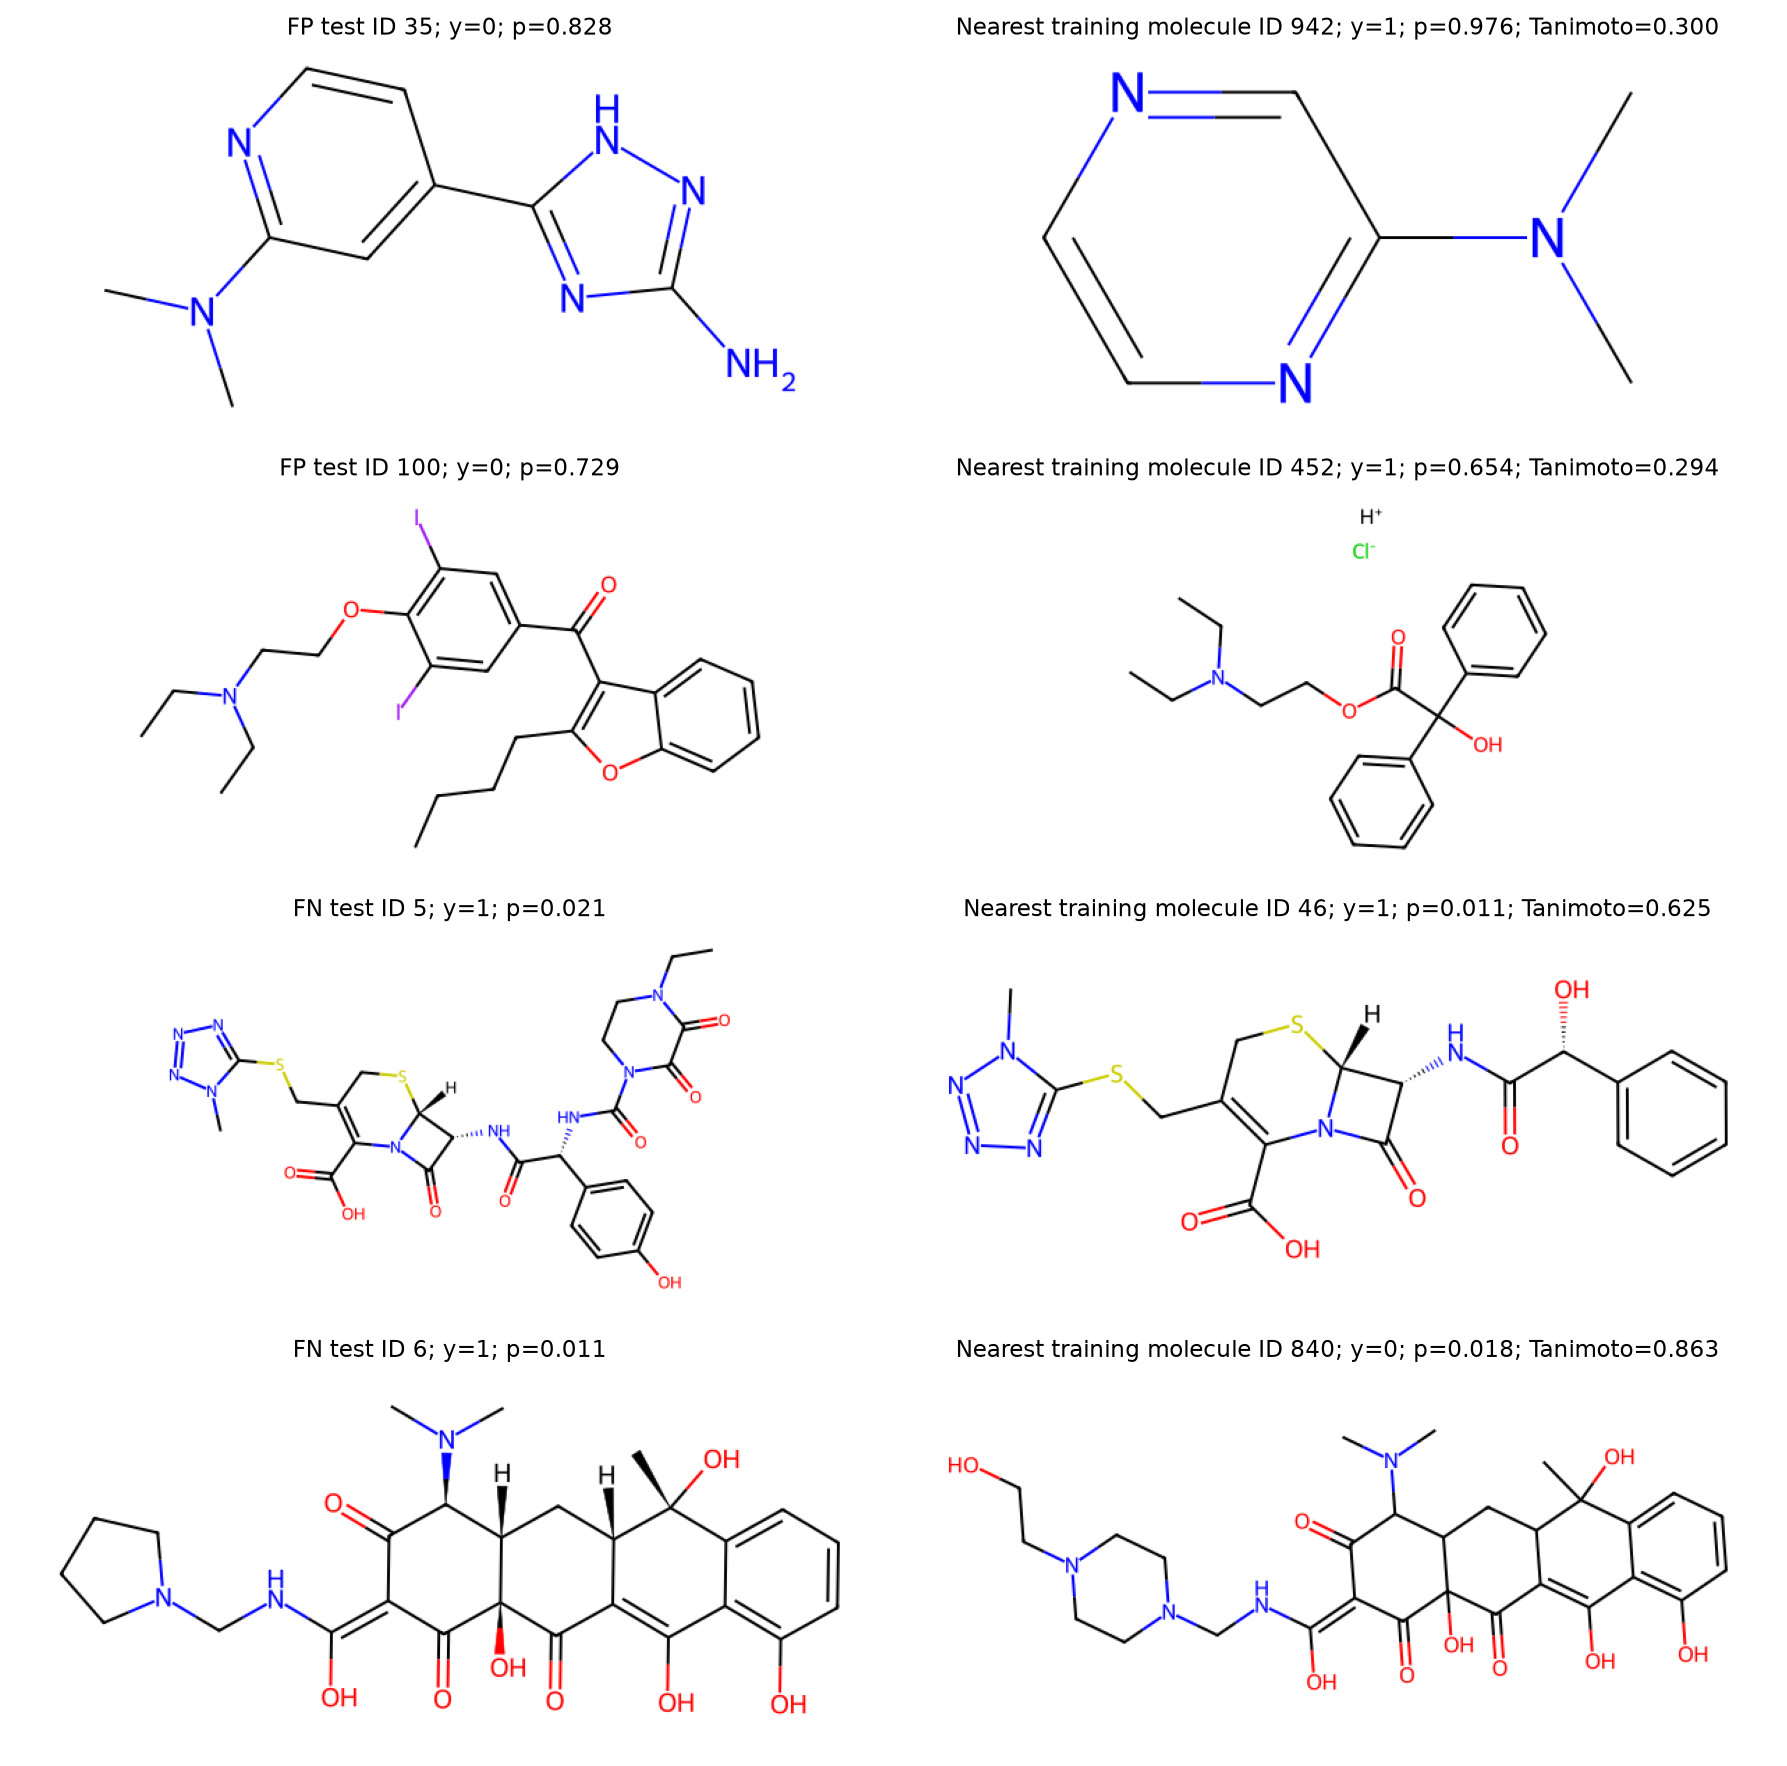

In [10]:
display(pd.DataFrame(summary['error_examples']))
display(Image(filename=str(FIG / 'error_pairs.png')))

## Limitations and reproducibility

- BBBP labels are curated research annotations and may be inconsistent; removed conflicts demonstrate uncertainty rather than eliminate it.
- Roughly two thousand compounds offer limited coverage of chemical space. One scaffold partition can have an unusual composition; training-seed SD does not measure split uncertainty.
- No external experimental validation, pharmacokinetic model, patient context or causal intervention is present. Predictions do not establish safety, efficacy, mechanism or clinical suitability.
- Exact canonical identity checks do not merge tautomers, salt forms or protonation variants. Nearest-neighbor similarity is limited by fingerprint hashing.
- This small GNN is a bounded baseline, not an exhaustive architecture search. A fingerprint model can outperform it.

The public source follows [MoleculeNet](https://doi.org/10.1039/C7SC02664A), [PyTorch Geometric](https://arxiv.org/abs/1903.02428), [Bemis–Murcko scaffolds](https://doi.org/10.1021/jm9602928), and the [RDKit documentation](https://www.rdkit.org/docs/GettingStartedInPython.html). Requirements pin package versions. Data and checkpoints are excluded from version control.

In [11]:
print('Environment:', json.dumps(summary['environment'], indent=2))
display(pd.Series(summary['timings'], name='Seconds'))
lock = json.loads((OUT / 'evaluation_lock.json').read_text())
print('Models frozen before evaluation:', len(lock['selection']))
print('Final evaluation completed:', lock['test_evaluation_completed'])

Environment: {
  "python": "3.12.12",
  "torch": "2.15.0",
  "torch_geometric": "2.8.1",
  "rdkit": "2026.09.1",
  "platform": "macOS-27.2-arm64-arm-64bit",
  "cpu_threads": 4
}


data_audit_and_splitting_seconds        2.431182
model_selection_seconds                86.708730
test_evaluation_and_figures_seconds     1.080229
total_seconds                          95.002930
Name: Seconds, dtype: float64

Models frozen before evaluation: 8
Final evaluation completed: True
